# Notebook 05 — Financial Exposure, Expected Loss & Insurance Risk

**Purpose:** quantify portfolio exposure from DS-3 and describe severity in DS-6 without claiming that the event sample estimates population failure probability.

## Method boundaries
- DS-3 is a cross-sectional bridge snapshot; it does not supply calibrated probability of default (PD), event time, or censoring.
- DS-6 is a historical event sample, not a denominator-complete exposure cohort. Its event frequency cannot be interpreted as annual failure probability.
- `loss_ratio` and repair/replacement values are audited before use. Reported event-loss distributions are conditional on the supplied event sample.
- Stress scenarios below are transparent sensitivities, not forecasts or actuarial estimates.


In [8]:
from pathlib import Path
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def find_project_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    candidates = [start, *start.parents]
    for p in candidates:
        if (p / "Data").exists() or (p / "data").exists():
            return p
    # Notebook often lives under ML/notebooks; walk up and use closest plausible project root.
    for p in candidates:
        if p.name.lower() in {"mat risk", "matrisk", "matrisk-ai"}:
            return p
    return start

if os.environ.get("MATRISK_PROJECT_ROOT"):
    ROOT = Path(os.environ["MATRISK_PROJECT_ROOT"]).expanduser().resolve()
else:
    ROOT = find_project_root()
    # In hosted/test environments where the uploaded CSVs live in /mnt/data,
    # use that directory as the root rather than its parent (/mnt).
    if (Path("/mnt/data") / "DS3_infrastructure_bridges_5000.csv").is_file():
        ROOT = Path("/mnt/data").resolve()
DATA_CANDIDATES = [
    Path(os.environ["MATRISK_DATA_ROOT"]).expanduser().resolve()
    if os.environ.get("MATRISK_DATA_ROOT") else None,
    ROOT / "Data", ROOT / "Data" / "raw", ROOT / "data" / "raw",
    ROOT.parent / "Data", ROOT.parent / "Data" / "raw",
    Path.cwd() / "Data", Path.cwd().parent / "Data",
    Path("/mnt/data"),
]
DATA_CANDIDATES = [p for p in DATA_CANDIDATES if p is not None]
OUT_DIR = ROOT / "ML" / "outputs" / "notebook_05"
OUT_DIR.mkdir(parents=True, exist_ok=True)

def locate(filename):
    for folder in DATA_CANDIDATES:
        path = folder / filename
        if path.is_file():
            print(f"Found {filename}: {path}")
            return path
    raise FileNotFoundError(
        f"Could not find {filename}. Searched: " +
        ", ".join(str(p) for p in DATA_CANDIDATES)
    )

DS3_PATH = locate("DS3_infrastructure_bridges_5000.csv")
DS6_PATH = locate("DS6_historical_failures_2000.csv")
bridges = pd.read_csv(DS3_PATH)
events = pd.read_csv(DS6_PATH)
print("DS-3:", bridges.shape, "| DS-6:", events.shape)
print("Outputs:", OUT_DIR.resolve())


Found DS3_infrastructure_bridges_5000.csv: C:\Users\Amey Ravindra Pandit\Downloads\MAT Risk\Data\raw\DS3_infrastructure_bridges_5000.csv
Found DS6_historical_failures_2000.csv: C:\Users\Amey Ravindra Pandit\Downloads\MAT Risk\Data\raw\DS6_historical_failures_2000.csv
DS-3: (5000, 24) | DS-6: (2000, 18)
Outputs: C:\Users\Amey Ravindra Pandit\Downloads\MAT Risk\ML\outputs\notebook_05


In [9]:
# 1. Schema and data-quality audit
required_bridge = ["bridge_id", "condition_rating", "loan_outstanding_M",
                   "replacement_cost_M", "insurance_premium_K_yr"]
required_event = ["event_id", "repair_cost_USD", "replacement_value_USD",
                  "loss_ratio", "event_year"]
for col in required_bridge:
    if col not in bridges.columns:
        raise ValueError(f"DS-3 missing required column: {col}")
for col in required_event:
    if col not in events.columns:
        raise ValueError(f"DS-6 missing required column: {col}")

bridge_audit = {
    "rows": int(len(bridges)),
    "duplicate_bridge_ids": int(bridges["bridge_id"].duplicated().sum()),
    "condition_rating_outside_1_9": int((~bridges["condition_rating"].between(1, 9)).sum()),
    "missing_loan_outstanding": int(bridges["loan_outstanding_M"].isna().sum()),
    "negative_loan_outstanding": int((bridges["loan_outstanding_M"] < 0).sum()),
    "negative_replacement_cost": int((bridges["replacement_cost_M"] < 0).sum()),
    "negative_insurance_premium": int((bridges["insurance_premium_K_yr"] < 0).sum()),
}
event_audit = {
    "rows": int(len(events)),
    "duplicate_event_ids": int(events["event_id"].duplicated().sum()),
    "repair_cost_gt_replacement_value": int((events["repair_cost_USD"] > events["replacement_value_USD"]).sum()),
    "nonpositive_replacement_value": int((events["replacement_value_USD"] <= 0).sum()),
    "negative_repair_cost": int((events["repair_cost_USD"] < 0).sum()),
    "loss_ratio_outside_0_1": int((~events["loss_ratio"].between(0, 1)).sum()),
}
print("Bridge portfolio audit:")
display(pd.Series(bridge_audit, name="value").to_frame())
print("Historical event sample audit:")
display(pd.Series(event_audit, name="value").to_frame())
pd.DataFrame([bridge_audit]).to_csv(OUT_DIR / "bridge_data_quality.csv", index=False)
pd.DataFrame([event_audit]).to_csv(OUT_DIR / "event_data_quality.csv", index=False)


Bridge portfolio audit:


,value
rows,5000
duplicate_bridge_ids,0
condition_rating_outside_1_9,5
missing_loan_outstanding,0
negative_loan_outstanding,0
negative_replacement_cost,0
negative_insurance_premium,0


Historical event sample audit:


,value
rows,2000
duplicate_event_ids,0
repair_cost_gt_replacement_value,85
nonpositive_replacement_value,0
negative_repair_cost,0
loss_ratio_outside_0_1,85


In [10]:
# 2. Portfolio exposure — only sums of observed fields, not calibrated risk estimates
numeric_cols = ["loan_outstanding_M", "replacement_cost_M", "insurance_premium_K_yr"]
for col in numeric_cols:
    bridges[col] = pd.to_numeric(bridges[col], errors="coerce")

portfolio = {
    "bridge_count": int(len(bridges)),
    "loan_outstanding_total_M": float(bridges["loan_outstanding_M"].sum(min_count=1)),
    "replacement_cost_total_M": float(bridges["replacement_cost_M"].sum(min_count=1)),
    "annual_premium_total_K": float(bridges["insurance_premium_K_yr"].sum(min_count=1)),
    "mean_loan_outstanding_M": float(bridges["loan_outstanding_M"].mean()),
    "median_condition_rating": float(bridges["condition_rating"].median()),
}
portfolio["loan_to_replacement_cost_ratio"] = (
    portfolio["loan_outstanding_total_M"] / portfolio["replacement_cost_total_M"]
    if portfolio["replacement_cost_total_M"] else np.nan
)
portfolio_df = pd.DataFrame([portfolio])
display(portfolio_df.T.rename(columns={0: "value"}))
portfolio_df.to_csv(OUT_DIR / "portfolio_exposure_summary.csv", index=False)

# Segment summaries help identify concentration, not causality.
segment_col = "bridge_type" if "bridge_type" in bridges.columns else None
if segment_col:
    segment = bridges.groupby(segment_col, dropna=False).agg(
        bridge_count=("bridge_id", "count"),
        loan_outstanding_M=("loan_outstanding_M", "sum"),
        replacement_cost_M=("replacement_cost_M", "sum"),
        annual_premium_K=("insurance_premium_K_yr", "sum"),
        mean_condition=("condition_rating", "mean"),
    ).reset_index()
    segment.to_csv(OUT_DIR / "exposure_by_bridge_type.csv", index=False)
    display(segment)


,value
bridge_count,5000.000000
loan_outstanding_total_M,1876.840000
replacement_cost_total_M,3409.350000
annual_premium_total_K,56385.100000
mean_loan_outstanding_M,0.375368
median_condition_rating,8.000000
loan_to_replacement_cost_ratio,0.550498


,bridge_type,bridge_count,loan_outstanding_M,replacement_cost_M,annual_premium_K,mean_condition
0,Highway,1739,671.45,1217.81,20100.1,7.462910
1,Interstate,1522,581.72,1053.70,17502.8,7.431012
2,Local Road,814,299.05,544.61,9165.8,7.469287
3,Pedestrian,409,140.51,258.12,4102.7,7.513447
4,Railroad,516,184.11,335.11,5513.7,7.416667


In [11]:
# 3. Event-sample severity analysis
# Do not estimate annual failure probability from this event-only dataset.
for col in ["repair_cost_USD", "replacement_value_USD", "loss_ratio", "event_year"]:
    events[col] = pd.to_numeric(events[col], errors="coerce")

valid_events = events[
    (events["replacement_value_USD"] > 0) &
    (events["repair_cost_USD"] >= 0) &
    events["loss_ratio"].notna()
].copy()
valid_events["recomputed_loss_ratio"] = (
    valid_events["repair_cost_USD"] / valid_events["replacement_value_USD"]
)
valid_events["loss_ratio_difference"] = (
    valid_events["loss_ratio"] - valid_events["recomputed_loss_ratio"]
)

severity_summary = {
    "event_rows_supplied": int(len(events)),
    "valid_rows_for_severity": int(len(valid_events)),
    "median_repair_cost_USD": float(valid_events["repair_cost_USD"].median()),
    "mean_repair_cost_USD": float(valid_events["repair_cost_USD"].mean()),
    "median_reported_loss_ratio": float(valid_events["loss_ratio"].median()),
    "mean_reported_loss_ratio": float(valid_events["loss_ratio"].mean()),
    "p95_repair_cost_USD": float(valid_events["repair_cost_USD"].quantile(0.95)),
    "p99_repair_cost_USD": float(valid_events["repair_cost_USD"].quantile(0.99)),
    "reported_loss_ratio_vs_recomputed_abs_diff_median": float(valid_events["loss_ratio_difference"].abs().median()),
}
display(pd.Series(severity_summary, name="value").to_frame())
pd.DataFrame([severity_summary]).to_csv(OUT_DIR / "event_severity_summary.csv", index=False)

# Empirical VaR / TVaR conditional on observed event sample only.
losses = valid_events["repair_cost_USD"].dropna().to_numpy()
tail_rows = []
for q in [0.90, 0.95, 0.99]:
    var = float(np.quantile(losses, q))
    tail = losses[losses >= var]
    tail_rows.append({
        "quantile": q, "empirical_VaR_USD": var,
        "empirical_TVaR_USD": float(tail.mean()) if len(tail) else np.nan,
        "tail_event_count": int(len(tail)),
        "interpretation": "Conditional on supplied event sample; not annual portfolio VaR",
    })
tail_df = pd.DataFrame(tail_rows)
display(tail_df)
tail_df.to_csv(OUT_DIR / "event_sample_var_tvar.csv", index=False)


,value
event_rows_supplied,2.000000e+03
valid_rows_for_severity,2.000000e+03
median_repair_cost_USD,2.048105e+05
mean_repair_cost_USD,5.389655e+05
median_reported_loss_ratio,2.057500e-01
mean_reported_loss_ratio,2.995872e-01
p95_repair_cost_USD,2.100388e+06
p99_repair_cost_USD,4.568820e+06
reported_loss_ratio_vs_recomputed_abs_diff_median,2.565925e-05


,quantile,empirical_VaR_USD,empirical_TVaR_USD,tail_event_count,interpretation
0,0.90,1290379.70,2757063.34,200,Conditional on supplied event sample; not annu...
1,0.95,2100387.85,3858565.56,100,Conditional on supplied event sample; not annu...
2,0.99,4568819.64,7850272.80,20,Conditional on supplied event sample; not annu...


,assumed_loss_fraction_of_replacement_value,hypothetical_gross_loss_M,hypothetical_loss_vs_total_loan,is_probability_estimate
0,0.01,34.0935,0.018165,False
1,0.03,102.2805,0.054496,False
2,0.05,170.4675,0.090827,False
3,0.10,340.9350,0.181654,False


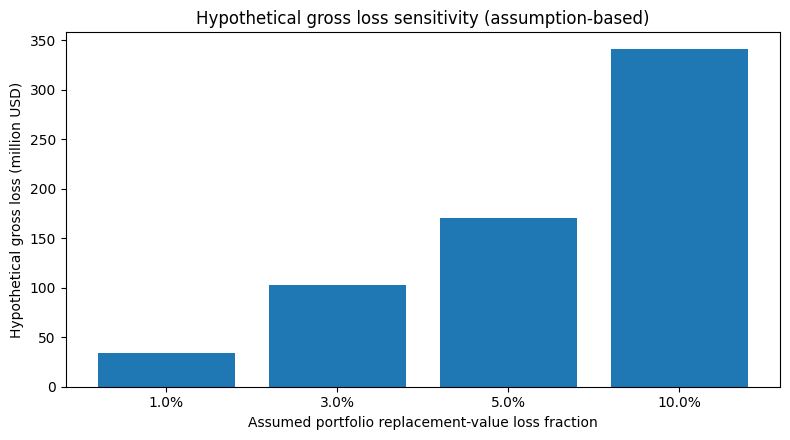

In [12]:
# 4. Transparent stress sensitivity — explicitly hypothetical
# Stress factors are user-editable assumptions, not estimated probabilities.
stress_factors = [0.01, 0.03, 0.05, 0.10]
portfolio_replacement = float(bridges["replacement_cost_M"].clip(lower=0).sum())
stress_rows = []
for factor in stress_factors:
    stress_rows.append({
        "assumed_loss_fraction_of_replacement_value": factor,
        "hypothetical_gross_loss_M": portfolio_replacement * factor,
        "hypothetical_loss_vs_total_loan": (
            portfolio_replacement * factor / portfolio["loan_outstanding_total_M"]
            if portfolio["loan_outstanding_total_M"] else np.nan
        ),
        "is_probability_estimate": False,
    })
stress_df = pd.DataFrame(stress_rows)
display(stress_df)
stress_df.to_csv(OUT_DIR / "hypothetical_stress_sensitivity.csv", index=False)

plt.figure(figsize=(8, 4.5))
plt.bar(
    (stress_df["assumed_loss_fraction_of_replacement_value"] * 100).astype(str) + "%",
    stress_df["hypothetical_gross_loss_M"]
)
plt.title("Hypothetical gross loss sensitivity (assumption-based)")
plt.xlabel("Assumed portfolio replacement-value loss fraction")
plt.ylabel("Hypothetical gross loss (million USD)")
plt.tight_layout()
plt.savefig(OUT_DIR / "hypothetical_stress_sensitivity.png", dpi=140)
plt.show()


In [13]:
# 5. Risk segmentation for review — transparent rule-based flags, not PD
review = bridges.copy()
review["condition_flag"] = np.select(
    [
        review["condition_rating"] <= 3,
        review["condition_rating"].between(4, 5),
        review["condition_rating"].between(6, 7),
        review["condition_rating"].between(8, 9),
    ],
    ["critical_or_poor", "fair", "good", "excellent"],
    default="invalid_or_missing",
)
review["remaining_thickness_fraction"] = (
    pd.to_numeric(review["remaining_thickness_mm"], errors="coerce") /
    pd.to_numeric(review["original_thickness_mm"], errors="coerce").replace(0, np.nan)
)
review["thinness_flag"] = review["remaining_thickness_fraction"] < 0.5
review["review_priority"] = (
    (review["condition_rating"] <= 3).astype(int) * 2
    + (pd.to_numeric(review["corrosion_rate_mm_yr"], errors="coerce") >
       pd.to_numeric(review["corrosion_rate_mm_yr"], errors="coerce").quantile(0.90)).astype(int)
    + review["thinness_flag"].fillna(False).astype(int)
)
review[[
    "bridge_id", "condition_rating", "condition_flag",
    "corrosion_rate_mm_yr", "remaining_thickness_fraction",
    "loan_outstanding_M", "replacement_cost_M",
    "review_priority"
]].to_csv(OUT_DIR / "bridge_risk_review_flags.csv", index=False)

priority_summary = review.groupby("condition_flag", dropna=False).agg(
    bridge_count=("bridge_id", "count"),
    loan_outstanding_M=("loan_outstanding_M", "sum"),
    replacement_cost_M=("replacement_cost_M", "sum"),
    mean_review_priority=("review_priority", "mean"),
).reset_index()
display(priority_summary)
priority_summary.to_csv(OUT_DIR / "risk_review_segment_summary.csv", index=False)


,condition_flag,bridge_count,loan_outstanding_M,replacement_cost_M,mean_review_priority
0,critical_or_poor,76,28.49,51.42,3.315789
1,excellent,2898,1090.22,1972.61,0.013803
2,fair,316,115.86,214.61,0.645570
3,good,1710,642.27,1170.71,0.115789


In [14]:
# 6. Export reproducibility summary and verify expected outputs
summary = {
    "notebook": "05_financial_exposure_expected_loss_insurance_risk",
    "dataset_paths": {"DS3": str(DS3_PATH.resolve()), "DS6": str(DS6_PATH.resolve())},
    "dataset_shapes": {"DS3": list(bridges.shape), "DS6": list(events.shape)},
    "portfolio_exposure": portfolio,
    "event_severity": severity_summary,
    "assumptions": {
        "stress_factors": stress_factors,
        "stress_scenarios_are_hypothetical": True,
        "event_sample_var_tvar_is_not_annual_portfolio_risk": True,
        "pd_lgd_expected_loss_not_calibrated": True,
    },
    "limitations": [
        "DS-3 is a snapshot and has no observed failure-time/censoring cohort.",
        "DS-6 is an event sample without a denominator-complete exposure population.",
        "Annual failure probability, PD, calibrated LGD and actuarial expected loss cannot be inferred from these files alone.",
        "Stress losses are sensitivities based on assumed fractions, not forecasts.",
        "Reported loss ratios are compared with repair cost divided by replacement value; definitions may differ.",
    ],
}
summary_path = OUT_DIR / "run_summary.json"
summary_path.write_text(json.dumps(summary, indent=2, default=str), encoding="utf-8")
expected = [
    "bridge_data_quality.csv", "event_data_quality.csv",
    "portfolio_exposure_summary.csv", "event_severity_summary.csv",
    "event_sample_var_tvar.csv", "hypothetical_stress_sensitivity.csv",
    "hypothetical_stress_sensitivity.png", "bridge_risk_review_flags.csv",
    "risk_review_segment_summary.csv", "run_summary.json",
]
missing = [name for name in expected if not (OUT_DIR / name).exists()]
if missing:
    raise RuntimeError(f"Expected outputs missing: {missing}")
print("Notebook 05 complete.")
print("Output directory:", OUT_DIR.resolve())
print("Created files:", expected)
print(json.dumps(summary, indent=2, default=str))


Notebook 05 complete.
Output directory: C:\Users\Amey Ravindra Pandit\Downloads\MAT Risk\ML\outputs\notebook_05
Created files: ['bridge_data_quality.csv', 'event_data_quality.csv', 'portfolio_exposure_summary.csv', 'event_severity_summary.csv', 'event_sample_var_tvar.csv', 'hypothetical_stress_sensitivity.csv', 'hypothetical_stress_sensitivity.png', 'bridge_risk_review_flags.csv', 'risk_review_segment_summary.csv', 'run_summary.json']
{
  "notebook": "05_financial_exposure_expected_loss_insurance_risk",
  "dataset_paths": {
    "DS3": "C:\\Users\\Amey Ravindra Pandit\\Downloads\\MAT Risk\\Data\\raw\\DS3_infrastructure_bridges_5000.csv",
    "DS6": "C:\\Users\\Amey Ravindra Pandit\\Downloads\\MAT Risk\\Data\\raw\\DS6_historical_failures_2000.csv"
  },
  "dataset_shapes": {
    "DS3": [
      5000,
      24
    ],
    "DS6": [
      2000,
      18
    ]
  },
  "portfolio_exposure": {
    "bridge_count": 5000,
    "loan_outstanding_total_M": 1876.84,
    "replacement_cost_total_M": 3409.3